# J5 · Interoperability: Limbdark.jl and the Python package

**Level:** intermediate · **Prerequisites:** [J1](J1_quickstart.ipynb) · **Run time:** ~2 min

**Covers:** Pizzetti.jl as a drop-in for [Limbdark.jl](https://github.com/rodluger/Limbdark.jl)
(Agol, Luger & Foreman-Mackey 2020): fluxes, gradients and timing; and agreement with the
Python package `pizzetti` on orbits and light curves.

In [1]:
using Pizzetti, BenchmarkTools, Plots
import Limbdark
include("theme.jl")

## 1. The same interface as Limbdark.jl

For polynomial limb darkening,

$$I(\mu) = 1 - \sum_{n \ge 1} u_n\,(1 - \mu)^n,$$

Pizzetti provides Limbdark.jl's functions `transit_poly(r, b, u_n)` (the flux) and
`transit_poly!(r, b, u_n, dfdrbu)` (the flux, and its gradient
$[\partial F/\partial r, \partial F/\partial b, \partial F/\partial u_1, \dots]$), so the two
packages can be swapped. Limbdark.jl evaluates the analytic solution of Agol et al. (2020);
Pizzetti the interior series (proven to $10^{-9}$ by default) and, near the limb, the exact
quadratic solution (degree ≤ 2) or the trapezoid rule and its interpolants (higher degrees).
The largest differences on a grid of radius ratios and impact parameters, up to first contact:

In [2]:
rows = []
for u in ([0.4, 0.25], [0.3, 0.2, 0.1], [0.5, -0.2, 0.3, -0.1])
    worst_f = worst_g = 0.0
    for r in (0.01, 0.05, 0.1, 0.2), b in range(0, 1 + r - 1e-9, length = 301)
        worst_f = max(worst_f, abs(Pizzetti.transit_poly(r, b, u) - Limbdark.transit_poly(r, b, u)))
        g1, g2 = zeros(length(u) + 2), zeros(length(u) + 2)
        Pizzetti.transit_poly!(r, b, u, g1)
        Limbdark.transit_poly!(r, b, u, g2)
        worst_g = max(worst_g, maximum(abs.(g1 .- g2)))
    end
    push!(rows, ("`$u`", length(u), sci(worst_f), sci(worst_g)))
end
table(["uₙ", "degree", "max abs ΔF", "max abs Δ gradient"], rows)

uₙ,degree,max abs ΔF,max abs Δ gradient
"[0.4, 0.25]",2,1.0e-15,2.5e-15
"[0.3, 0.2, 0.1]",3,7.0e-10,1.8e-15
"[0.5, -0.2, 0.3, -0.1]",4,7.3e-10,3.4e-15


For degree ≤ 2 both codes are exact and agree to rounding. For higher degrees, Pizzetti's
interior samples are the series within its proven tolerance of $10^{-9}$ (the default); with a
tighter `series_tol` they agree to rounding as well. Along one transit chord, $r = 0.1$, cubic
law:

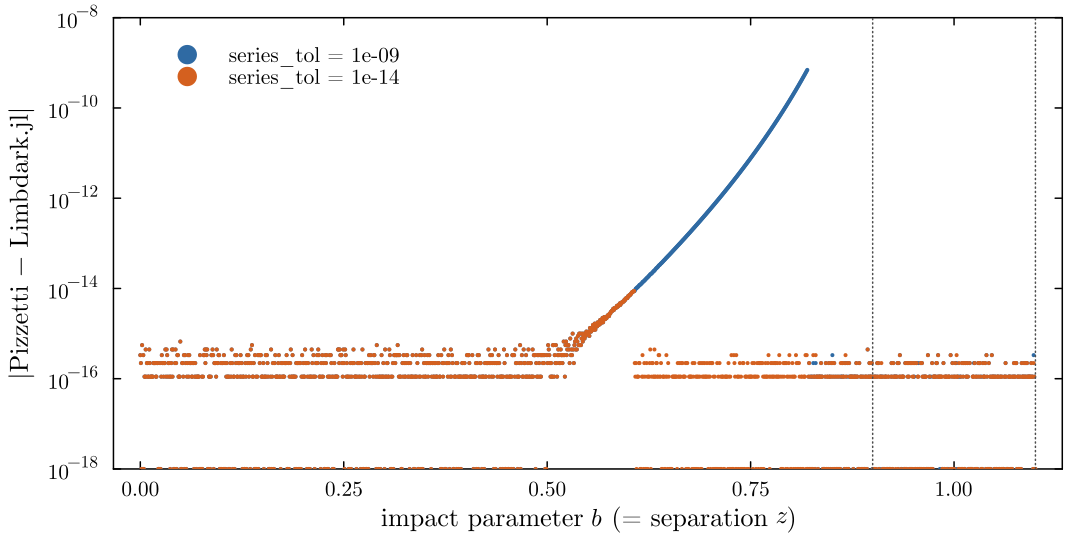

In [3]:
u3 = [0.3, 0.2, 0.1]
bs = range(0, 1.1 - 1e-9, length = 1500)
dF(series_tol) = [abs(Pizzetti.occult(b, 0.1, Polynomial(u3); series_tol = series_tol) - Limbdark.transit_poly(0.1, b, u3)) for b in bs]
plt = plot(xlabel = L"impact parameter $b$ (= separation $z$)", ylabel = "|Pizzetti − Limbdark.jl|",
           yscale = :log10, ylims = (1e-18, 1e-8), legend = :topleft, size = (720, 360))
for (τ, col) in ((1e-9, COLORS.series), (1e-14, COLORS.limb))
    scatter!(plt, bs, max.(dF(τ), 1e-18), ms = 1.5, msw = 0, color = col, label = "series_tol = $(sci(τ, 1))")
end
vline!(plt, [0.9, 1.1], color = :gray30, ls = :dot, lw = 1, label = "")
plt

(Exact agreement is drawn at $10^{-18}$; the dotted lines mark second and first contact.)

## 2. Speed

Single calls first. The per-light-curve set-up is included in Pizzetti's number, which
favours Limbdark.jl:

In [4]:
u = [0.4, 0.25]
rows = [(b, @sprintf("%.0f ns", 1e9 * @belapsed(Pizzetti.transit_poly(0.1, $b, $u))),
         @sprintf("%.0f ns", 1e9 * @belapsed(Limbdark.transit_poly(0.1, $b, $u)))) for b in (0.3, 0.95)]
table(["b", "Pizzetti", "Limbdark.jl"], rows)

b,Pizzetti,Limbdark.jl
0.3,66 ns,1898 ns
0.95,70 ns,1951 ns


A light curve of $10^4$ samples, with Pizzetti's `Occultor` set up once (the way it is meant to
be used), against Limbdark.jl called per sample and with its transit structure re-used:

In [5]:
z = collect(range(0, 1.1, length = 10_000))
o = Occultor(0.1, Polynomial(u))
out, out2 = similar(z), similar(z)
ts = Limbdark.transit_init(0.1, 0.5, u, false)
function limbdark_lc!(out, ts, z)
    for i in eachindex(z)
        ts.b = z[i]
        out[i] = Limbdark.transit_poly!(ts)
    end
    out
end
t1 = @belapsed evaluate!($out, $o, $z)
t2 = @belapsed [Limbdark.transit_poly(0.1, zi, $u) for zi in $z]
t3 = @belapsed limbdark_lc!($out2, $ts, $z)
table(["10 000 samples, quadratic law", "time"],
      [("Pizzetti, `evaluate!` with an `Occultor`", @sprintf("%.3f ms", 1e3t1)),
       ("Limbdark.jl, `transit_poly` per sample", @sprintf("%.3f ms", 1e3t2)),
       ("Limbdark.jl, re-used transit structure", @sprintf("%.3f ms", 1e3t3)),
       ("largest difference of the light curves", sci(maximum(abs.(out .- out2))))])

"10 000 samples, quadratic law",time
"Pizzetti, evaluate! with an Occultor",0.174 ms
"Limbdark.jl, transit_poly per sample",25.286 ms
"Limbdark.jl, re-used transit structure",0.723 ms
largest difference of the light curves,7.2e-10


`transit_poly` uses the closed forms for degree ≤ 2, while `evaluate!` uses the interior
series wherever its proven bound allows; hence the difference of $7 \times 10^{-10}$, within
the default tolerance of $10^{-9}$.

## 3. The same light curves as the Python package

The repository contains test vectors written by the Python package
(`testdata/python_lightcurves.json`): Keplerian orbits, circular and eccentric, five laws,
radius ratios 0.009–0.3, computed with the interior series switched off and quadrature at the
limb, so that they do not depend on the series truncation. Python's `TransitParams` fields
(`inc`, `ecc`, `w`, `u`, `limb_dark`) are accepted as keywords, so parameters move between the
two languages without translation:

In [6]:
using JSON
d = JSON.parsefile(joinpath(@__DIR__, "..", "..", "testdata", "python_lightcurves.json"))
rows = map(d["cases"]) do cs
    P = cs["params"]
    prm = TransitParams(t0 = P["t0"], per = P["per"], rp = P["rp"], a = P["a"], inc = P["inc"], ecc = P["ecc"],
                        w = P["w"], u = Float64.(P["u"]), limb_dark = P["limb_dark"])
    t = Float64.(cs["t"])
    (P["limb_dark"], P["rp"], P["ecc"], sci(maximum(abs.(rsky(t, prm) .- Float64.(cs["z"])))),
     sci(maximum(abs.(light_curve(t, prm) .- Float64.(cs["flux"])))))
end
table(["law", "rp", "e", "max abs Δz", "max abs ΔF (default settings)"], rows)

law,rp,e,max abs Δz,max abs ΔF (default settings)
quadratic,0.1,0.0,2.8e-14,5.1e-10
power2,0.02,0.0,2.6e-13,5.1e-11
nonlinear,0.08,0.3,1.5e-14,5.1e-10
squareroot,0.15,0.1,7.7e-15,7.7e-10
power2,0.3,0.0,6.8e-15,8.0e-10
nonlinear,0.00916,0.0167,0,1.4e-11


The orbits agree to rounding, the fluxes to within the series tolerance of $10^{-9}$.

## What you learned

- `Pizzetti.transit_poly` and `transit_poly!` are drop-in replacements for Limbdark.jl's,
  with the same fluxes and gradients;
- Pizzetti.jl and the Python `pizzetti` agree on orbits to rounding and on fluxes to within the
  series tolerance.

**Next:** [J6 · The limb integral in Bartky's variable](J6_bartky.ipynb). The
[Python notebooks](../../examples) cover fitting with `MarginalTransitModel`, error control and
performance in more depth.